# C1 | Customer portfolio concentration
**Moisés Medina and Ignacia Castillo** · Business Intelligence · 26 September 2026

This notebook reproduces the C1 data preparation and diagnostic EDA. The decision, population, formulas, row treatments and interpretive limits are explained in the accompanying report. The source CSV is an uncleaned, date-filtered copy of the UCI Online Retail file; the original rows are preserved.

**From W1 to C1.** We compared customer-value concentration (Candidate A) with monitoring C-coded cancellation records (Candidate B). We chose A because it has a directly observable value numerator, identifiable customers and a measurable missing-ID boundary. B remains a useful descriptive process question, but the file cannot link a C record to its original purchase or provide its reason. We also set aside a November/Christmas explanation: one annual cycle does not establish seasonality.

## 1. Rebuild and validate
`c1_analysis.py` checks schema, date range, row counts, mutually exclusive analytical groups, positive eligible line values, and invoice-to-customer consistency. It writes `prepared_lines.csv` with row-level flags and never overwrites the source extract.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from c1_analysis import ROOT, main
main()
DATA = ROOT / 'data'
FIGURES = ROOT / 'analysis' / 'figures'
metrics = json.loads((DATA / 'report_metrics.json').read_text(encoding='utf-8'))
display(pd.Series({k: metrics[k] for k in ['source_rows', 'eligible_purchase_lines', 'eligible_c_lines', 'other_retained', 'missing_customer_id_raw', 'exact_duplicates_raw', 'nonpositive_price_raw', 'outside_merchandise_rule_raw']}))

{
  "baseline": {
    "customers": 4293,
    "top_decile_ids": 430,
    "known_value_gbp": 8233040.5600000005,
    "top_decile_share_pct": 60.50013933127034,
    "known_id_value_coverage_pct": 85.66276814655409
  },
  "customer_value_stats": {
    "n": 4293,
    "mean": 1917.7825669694853,
    "median": 652.8,
    "q1": 301.9,
    "q3": 1572.71,
    "iqr": 1270.81,
    "mad": 451.19999999999993,
    "p90": 3413.9360000000015,
    "p99": 16922.728799999957,
    "max": 267410.0
  },
  "sensitivity": [
    {
      "scenario": "baseline",
      "customers": 4293,
      "top_decile_ids": 430,
      "known_value_gbp": 8233040.5600000005,
      "top_decile_share_pct": 60.50013933127034,
      "known_id_value_coverage_pct": 85.66276814655409
    },
    {
      "scenario": "drop exact repeat rows",
      "customers": 4293,
      "top_decile_ids": 430,
      "known_value_gbp": 8210203.9,
      "top_decile_share_pct": 60.57682696528401,
      "known_id_value_coverage_pct": 85.63196705332545
    }

source_rows                     516384
eligible_purchase_lines         500531
eligible_c_lines                  8351
other_retained                    7502
missing_customer_id_raw         127216
exact_duplicates_raw              4989
nonpositive_price_raw             2463
outside_merchandise_rule_raw      5072
dtype: int64

The quality flags overlap. The row groups do not: each source line is assigned to priced purchase, priced C record, or other retained. A blank customer ID excludes a line only from customer ranks; it remains in total eligible value and coverage calculations. Zero prices are not filled with another invoice's price because that would invent a charge.

In [2]:
quality = pd.read_csv(DATA / 'quality_by_month.csv')
display(quality)
prepared = pd.read_csv(DATA / 'prepared_lines.csv', usecols=['row_group', 'missing_customer_id', 'exact_duplicate'])
assert len(prepared) == metrics['source_rows']
display(prepared['row_group'].value_counts())
del prepared

,month,rows,missing_customer_id,missing_description,exact_duplicate,nonpositive_price,outside_merchandise_rule,negative_non_c_quantity
0,2010-12,42481,15631,125,500,273,470,70
1,2011-01,35147,13235,114,247,140,321,96
2,2011-02,27707,7344,65,228,127,405,48
3,2011-03,36748,8926,165,309,246,455,134
4,2011-04,29916,6718,226,215,261,304,186
5,2011-05,37030,8122,138,248,245,448,117
6,2011-06,36874,9038,91,265,186,433,107
7,2011-07,39518,12016,155,251,188,402,117
8,2011-08,35284,7622,82,220,133,330,50
9,2011-09,50226,9404,99,365,160,406,98


row_group
priced_purchase    500531
priced_C_record      8351
other_retained       7502
Name: count, dtype: int64

## 2. Provisional KPI and data-quality guardrail
For identifiable customers, sum eligible positive purchase-line value (`Quantity × UnitPrice`) over the observed year. Rank IDs by that value. The KPI is the share of known-ID value held by the highest-value `ceil(10% × N)` IDs. Known-ID value coverage is a mandatory guardrail, not another estimate of the same construct. This is recorded gross purchase value, not reconciled net revenue, profit, churn, or lifetime value.

In [3]:
display(pd.Series(metrics['baseline']))
display(pd.Series(metrics['customer_value_stats']))
display(pd.Series(metrics['customer_invoice_stats']))
print('Invoice-frequency/value Pearson:', round(metrics['pearson_customer_invoice_count_vs_value'], 3))
print('Invoice-frequency/value Spearman:', round(metrics['spearman_customer_invoice_count_vs_value'], 3))
print('Purchase invoices entirely without ID:', metrics['purchase_invoices_entirely_without_id'])
print('Purchase invoices with a mix of known and missing IDs:', metrics['purchase_invoices_with_mixed_known_missing_id'])

customers                      4.293000e+03
top_decile_ids                 4.300000e+02
known_value_gbp                8.233041e+06
top_decile_share_pct           6.050014e+01
known_id_value_coverage_pct    8.566277e+01
dtype: float64

n           4293.000000
mean        1917.782567
median       652.800000
q1           301.900000
q3          1572.710000
iqr         1270.810000
mad          451.200000
p90         3413.936000
p99        16922.728800
max       267410.000000
dtype: float64

n         4293.000000
mean         4.105521
median       2.000000
q1           1.000000
q3           4.000000
iqr          3.000000
mad          1.000000
p90          8.000000
p99         28.000000
max        197.000000
dtype: float64

Invoice-frequency/value Pearson: 0.569
Invoice-frequency/value Spearman: 0.803
Purchase invoices entirely without ID: 1328
Purchase invoices with a mix of known and missing IDs: 0


## 3. Distribution and association after validation
The mean and median describe different customers because the observed value distribution is strongly skewed. The ECDF and quantiles show its shape without assuming normality. Pearson and Spearman differ in this long-tailed setting. Invoice frequency and value are associated, but value partly accumulates through more invoices; this relationship is descriptive and does not show that an intervention will cause repeat purchases.

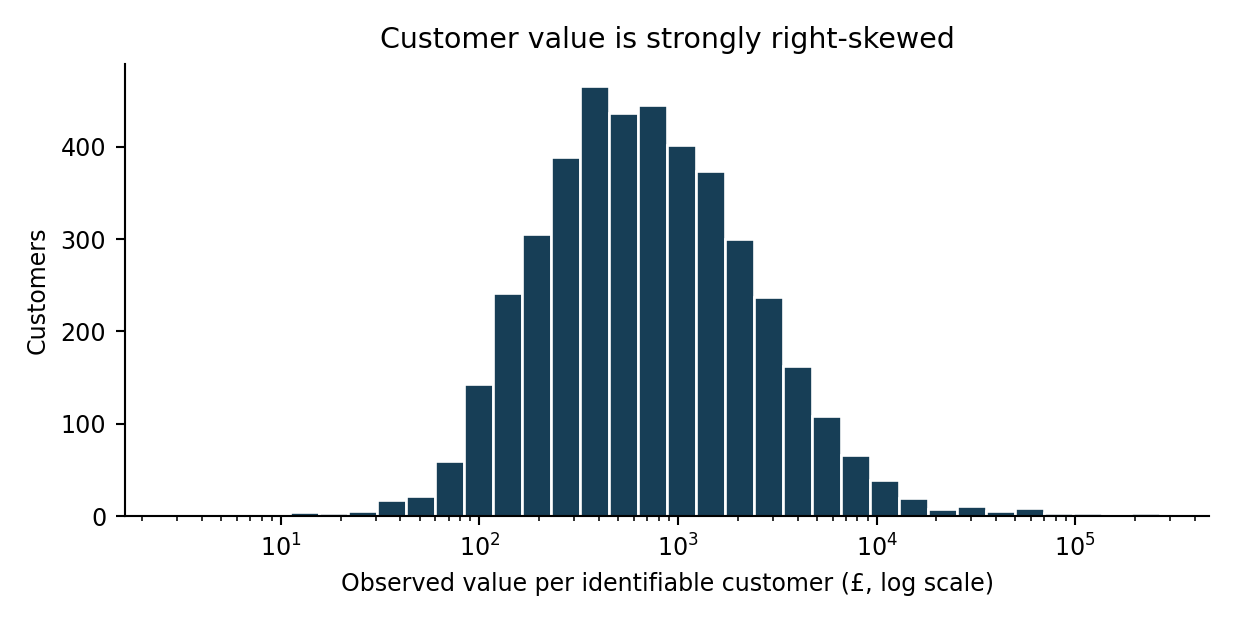

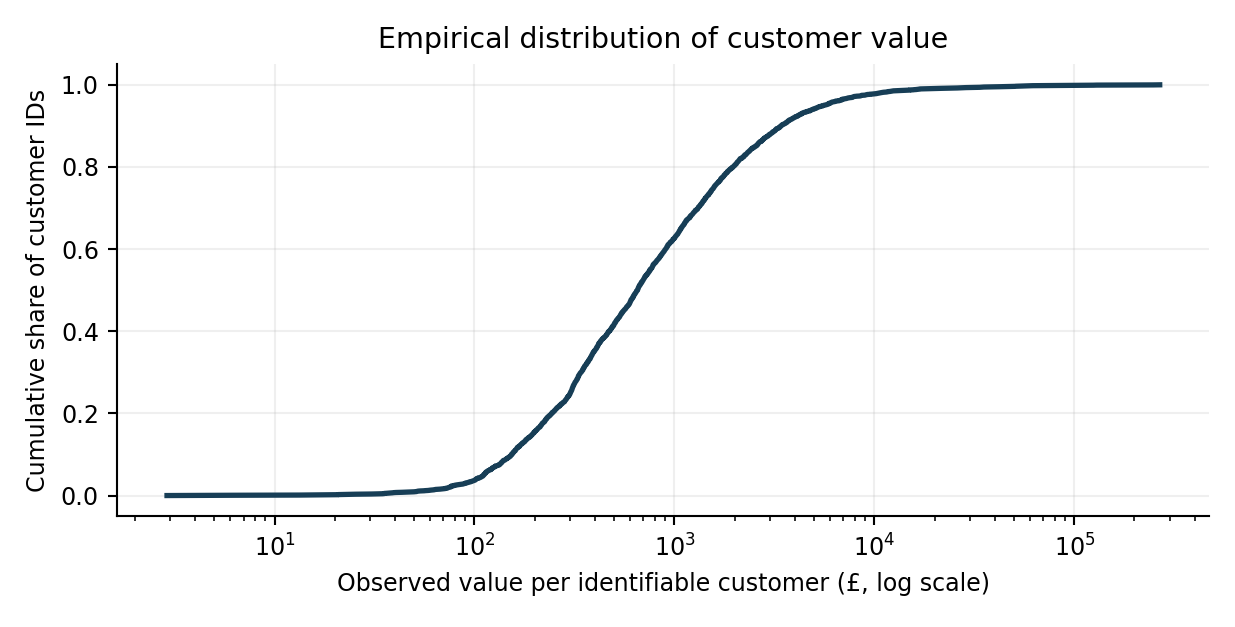

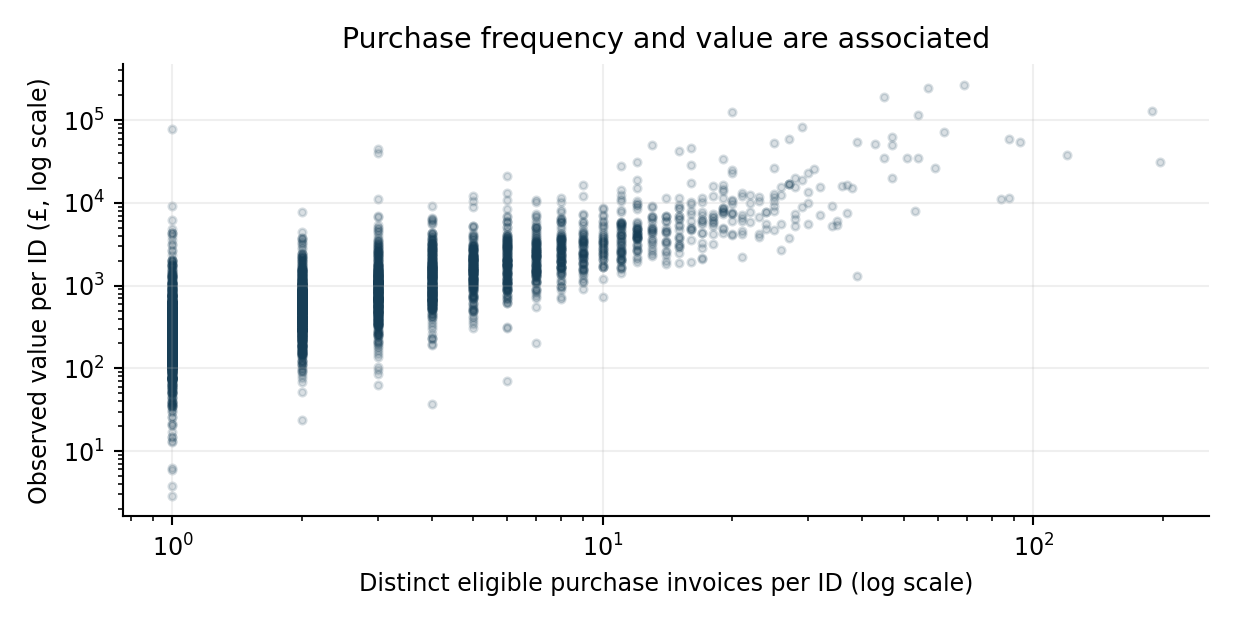

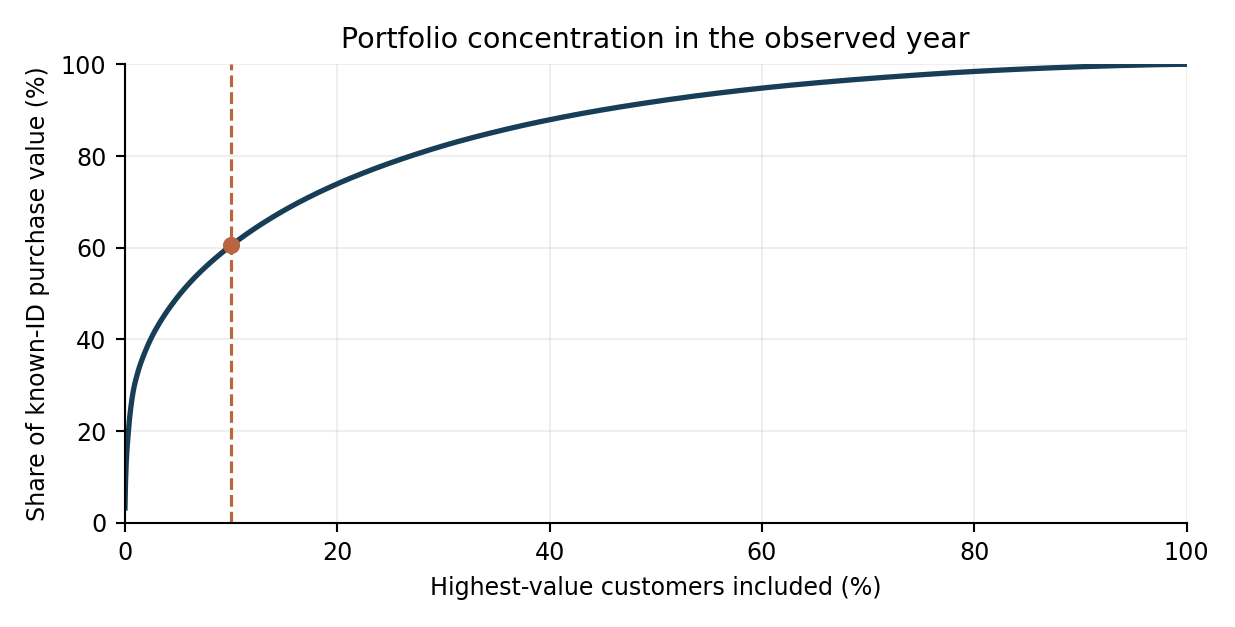

In [4]:
for name in ['customer_value_distribution.png', 'customer_value_ecdf.png', 'frequency_value_scatter.png', 'concentration_curve.png']:
    display(Image(filename=str(FIGURES / name)))

In [5]:
frequency_groups = pd.read_csv(DATA / 'invoice_frequency_groups.csv')
display(frequency_groups.round(2))

,observed_invoice_group,customers,observed_value_gbp,median_customer_value_gbp,customer_share_pct,known_value_share_pct
0,one invoice,1551,644425.56,262.20,36.13,7.83
1,two or more invoices,2742,7588615.00,1140.28,63.87,92.17


## 4. Segmentation and coverage
Each monthly top-decile calculation reranks active known IDs, so its percentages are not directly equivalent to the full-year KPI. Monthly changes in known-ID coverage can change the observed customer population. UK and non-UK rows are descriptive customer-country segments, not verified shipping markets or a causal comparison.

,month,purchase_value_gbp,known_id_customers,known_id_coverage_pct,top_decile_share_pct
0,2010-12,770510.16,883,73.51,49.37
1,2011-01,669871.64,739,84.05,57.21
2,2011-02,506167.81,757,87.45,46.29
3,2011-03,688241.68,973,84.83,46.96
4,2011-04,513866.58,853,88.52,42.48
5,2011-05,737411.85,1054,89.43,46.44
6,2011-06,736055.65,990,88.81,54.18
7,2011-07,685260.50,946,86.11,48.36
8,2011-08,722585.61,933,87.97,51.34
9,2011-09,1027021.96,1259,91.47,50.67


,segment,purchase_lines,purchase_value_gbp,customers,top_decile_ids,known_value_gbp,top_decile_share_pct,known_id_value_coverage_pct
0,United Kingdom,458301,8132965.10,3882,389,6783370.11,58.43,83.41
1,Other countries,42230,1478025.46,411,42,1449670.45,69.17,98.08


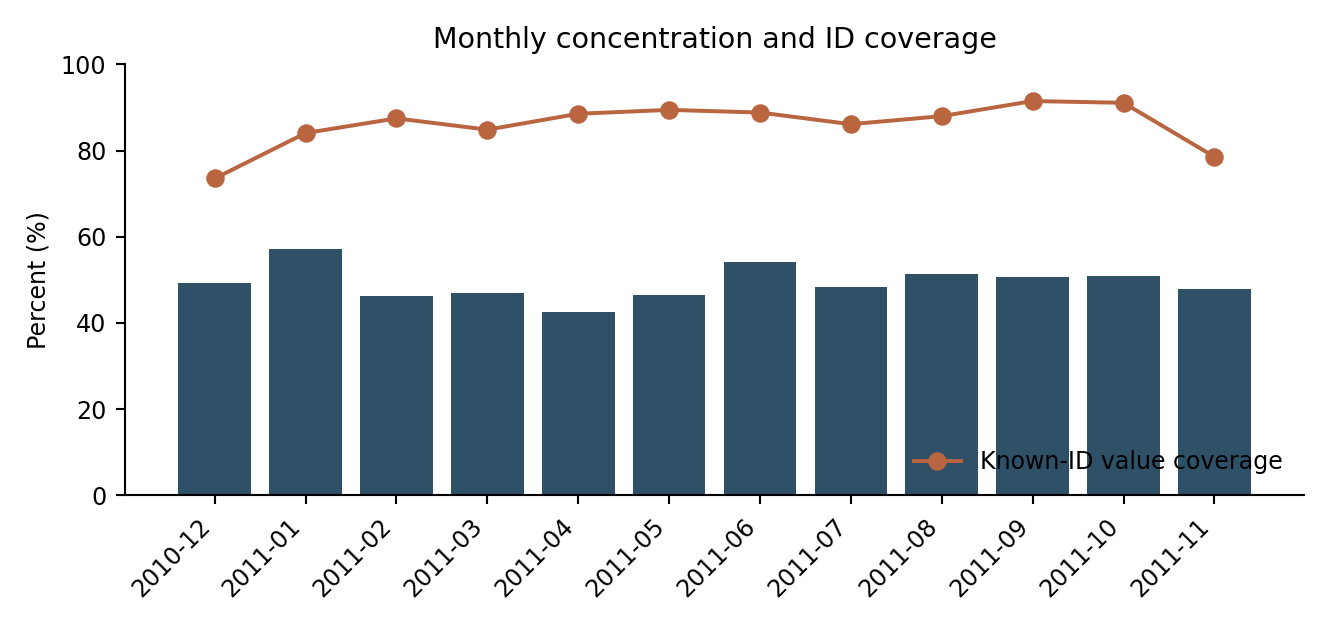

In [6]:
monthly = pd.read_csv(DATA / 'monthly_kpi.csv')
segments = pd.read_csv(DATA / 'uk_segment_kpi.csv')
display(monthly[['month', 'purchase_value_gbp', 'known_id_customers', 'known_id_coverage_pct', 'top_decile_share_pct']].round(2))
display(segments.round(2))
display(Image(filename=str(FIGURES / 'monthly_concentration_coverage.png')))

## 5. Sensitivity and decision limit
Removing exact repeats, narrowing or broadening the stock-code rule, and removing the largest ID are alternative populations, not repairs silently applied to the baseline. The last scenario diagnoses dependence on one account; it changes the target population. We cannot determine whether missing-ID purchases are distributed like identified purchases.

In [7]:
sensitivity = pd.read_csv(DATA / 'sensitivity.csv')
display(sensitivity[['scenario', 'customers', 'known_value_gbp', 'top_decile_share_pct', 'known_id_value_coverage_pct']].round(2))
assert abs(sensitivity.loc[0, 'top_decile_share_pct'] - metrics['baseline']['top_decile_share_pct']) < 1e-9

,scenario,customers,known_value_gbp,top_decile_share_pct,known_id_value_coverage_pct
0,baseline,4293,8233040.56,60.50,85.66
1,drop exact repeat rows,4293,8210203.90,60.58,85.63
2,strict five-digit codes,4273,7521298.01,60.41,85.68
3,all positive priced stock codes,4297,8393215.11,60.58,83.70
4,remove largest known ID (diagnostic),4292,7965630.56,59.22,85.25


**Main insight.** The concentration reflects a portfolio pattern, not just one extreme ID: the top 430 of 4,293 known IDs account for 60.5% of known-ID value; the largest single ID accounts for 3.25%. The 36.1% observed in only one eligible purchase invoice contribute 7.8% of known-ID value, while the two-or-more-invoice group contributes 92.2%. This supports a closer review of major observed accounts and ID capture. It does not prove loyalty or justify spending on retention. The unknown-ID share (14.3% of eligible value), one-year window, product-code convention and absence of linked payments prevent a claim about all customers, lifetime value or profit.